In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv("demand_forecasting.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [3]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

In [5]:
print(df["Seasonality"].unique())
print(df["Category"].unique())
print(df["Region"].unique())
print(df["Weather Condition"].unique())

['Winter' 'Spring' 'Summer' 'Autumn']
['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']
['North' 'South' 'East' 'West']
['Snowy' 'Cloudy' 'Sunny' 'Rainy']


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.shape

(76000, 16)

In [8]:
df["Date"]=pd.to_datetime(df["Date"],format="mixed",errors="coerce")

In [9]:
df["Year"]=df["Date"].dt.year
df["month"]=df["Date"].dt.month
df["week_day"]=df["Date"].dt.dayofweek

In [10]:
df["Final Price"]=df["Price"]*(1-(df["Discount"]/100))

In [11]:
df["Sales value"]=df["Units Sold"]*df["Final Price"]

In [12]:
df["price to competitor"] = np.where(df["Final Price"]>df["Competitor Pricing"],"High","Low")

# Sales by Category

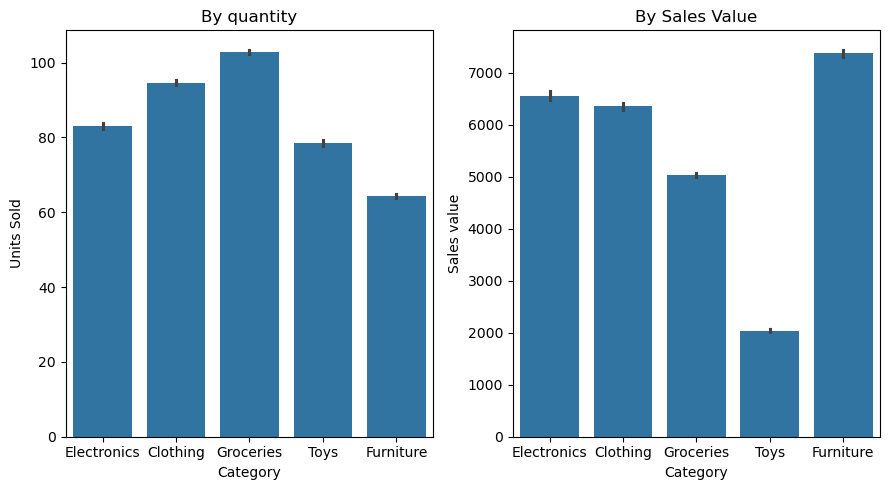

In [13]:
plt.figure(figsize=(9,5))
plt.subplot(1,2,1)
sns.barplot(data=df, x="Category", y="Units Sold")
plt.title("By quantity")
plt.subplot(1,2,2)
sns.barplot(data=df, x="Category", y="Sales value")
plt.title("By Sales Value")
plt.tight_layout()
plt.show()

### Conclusion
**Groceries has sold highest number of units and furniture is the least. but on the basis of sales value furniture is the top**

# Effect of Promotion on sales 

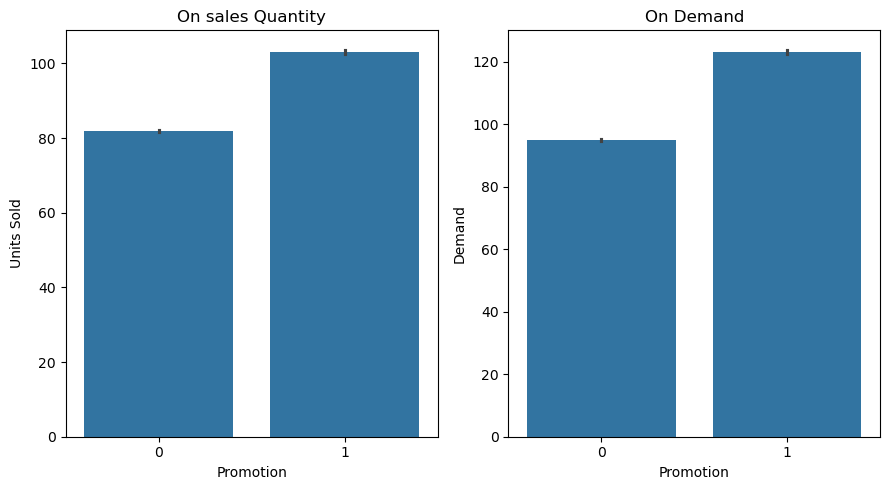

In [14]:
plt.figure(figsize=(9,5))
plt.subplot(1,2,1)
sns.barplot(data=df, x="Promotion", y="Units Sold")
plt.title("On sales Quantity")
plt.subplot(1,2,2)
sns.barplot(data=df, x="Promotion", y="Demand")
plt.title("On Demand")
plt.tight_layout()
plt.show()

### Conclusion
**Promotion is helping in increasing sales**

# Effect of Epidemic on sales 

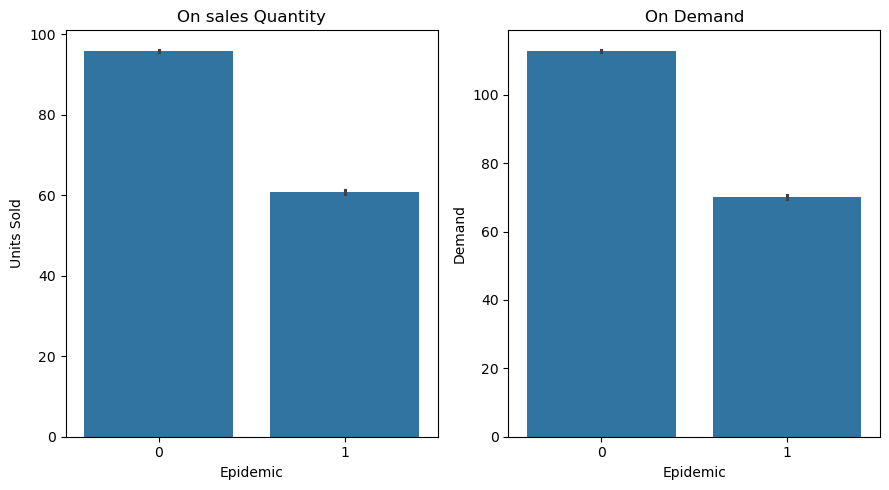

In [15]:
plt.figure(figsize=(9,5))
plt.subplot(1,2,1)
sns.barplot(data=df, x="Epidemic", y="Units Sold")
plt.title("On sales Quantity")
plt.subplot(1,2,2)
sns.barplot(data=df, x="Epidemic", y="Demand")
plt.title("On Demand")
plt.tight_layout()
plt.show()

### Conclusion
**Epidemic causes decrease in sales**

# Effect of Season and weather condition on Sales

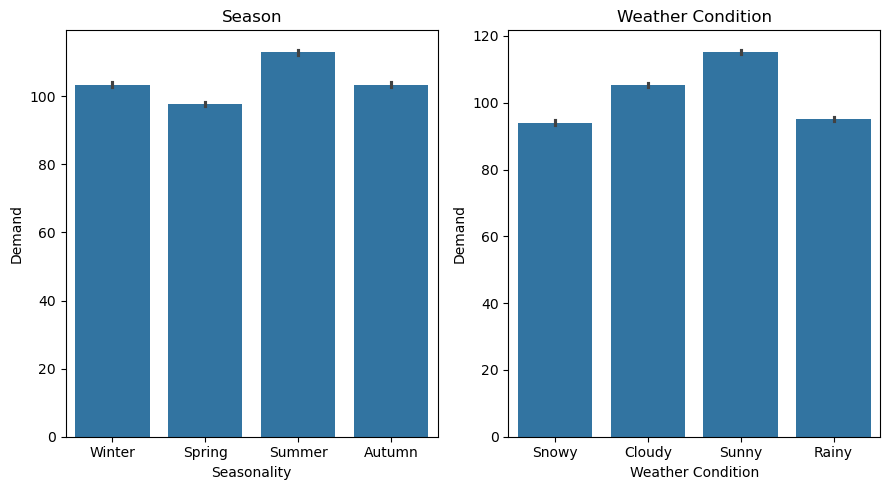

In [16]:
plt.figure(figsize=(9,5))
plt.subplot(1,2,1)
sns.barplot(data=df, x="Seasonality", y="Demand")
plt.title("Season")
plt.subplot(1,2,2)
sns.barplot(data=df, x="Weather Condition", y="Demand")
plt.title("Weather Condition")
plt.tight_layout()
plt.show()

### Conclusion
**Summer season has highest amount of sales and spring hold the least. In case of weather conditon during sunny weather has the highest sale and snowy weather hold the least**

# Month and Day wise sales

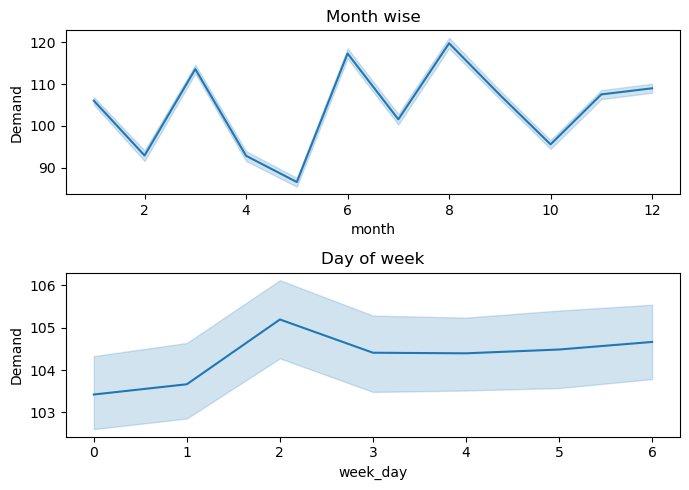

In [17]:
plt.figure(figsize=(7,5))
plt.subplot(2,1,1)
sns.lineplot(data=df,x="month",y="Demand")
plt.title("Month wise")
plt.subplot(2,1,2)
sns.lineplot(data=df,x="week_day",y="Demand")
plt.title("Day of week")
plt.tight_layout()
plt.show()

### Conclusion
**August month has the highest sales followed by june and month May has the least sales. on the basis of day of the week wednesday hold highest and monday has the least**

# Demand by region

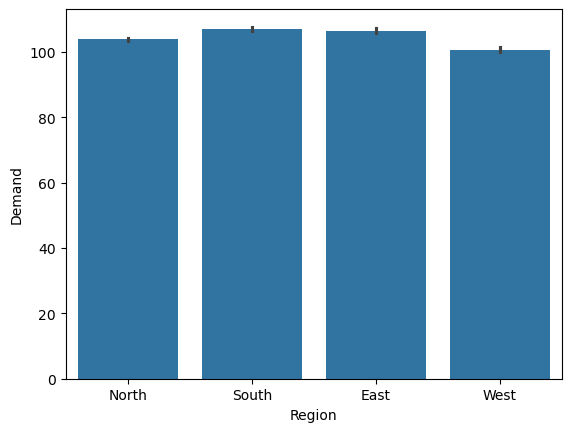

In [18]:
sns.barplot(data=df,x="Region",y="Demand")
plt.show()

### Conclusion
**All region hold almost same level of Demand with south region having slight upper hand**

# Price and demand comparison based on competitor pricing

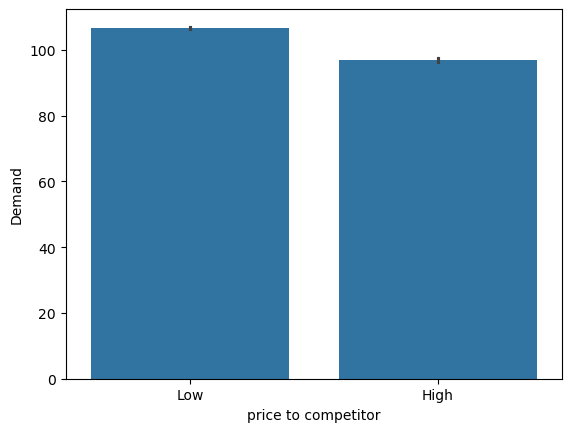

In [19]:
sns.barplot(data=df,x="price to competitor",y="Demand")
plt.show()

### Conclusion
**Demand is more on products having price less than competitor**

# Demand on different category and its price Relation to competitor

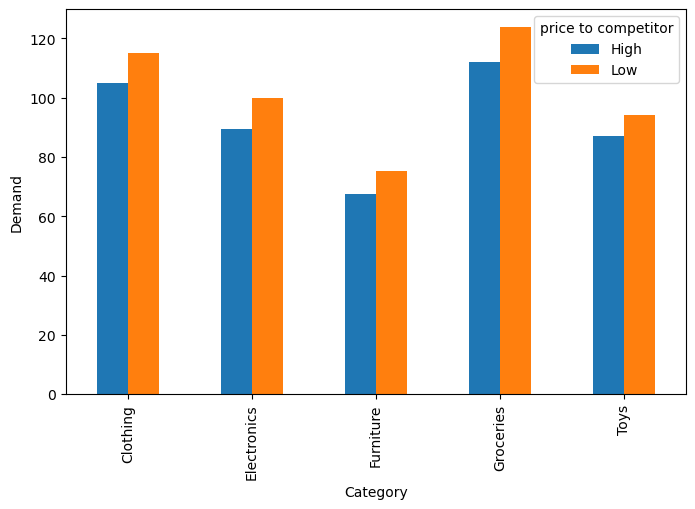

In [20]:
pivot=df.pivot_table(index="Category",columns="price to competitor",values="Demand",aggfunc="mean")
pivot.plot(kind="bar",figsize=(8,5))
plt.ylabel("Demand")
plt.show()

### Conclusion
**In all category price less than competitor has more demand**

# Correlation Heat Map

In [21]:
numercols=df.select_dtypes(include="number").columns

In [22]:
correlation=df[['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Promotion', 'Competitor Pricing', 'Epidemic', 'Demand']].corr()


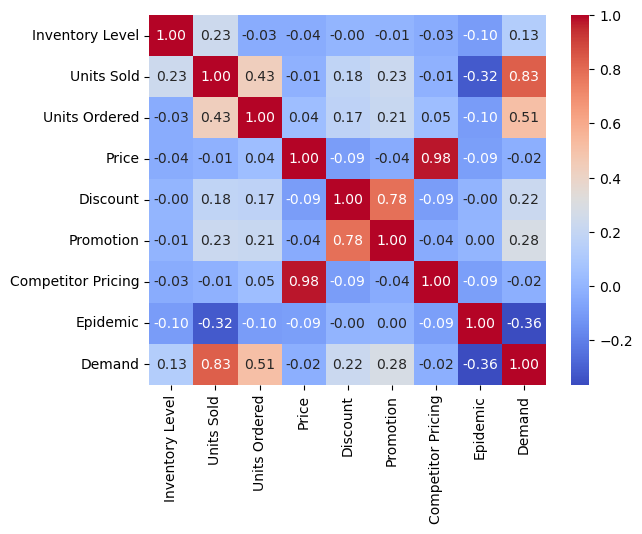

In [23]:
sns.heatmap(data=correlation,cmap="coolwarm",annot=True,fmt="0.2f")
plt.show()

# Export Processed Data

In [24]:
df.to_csv("preprocessed_data.csv",index=False)